In [3]:
%pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 699.0 kB/s eta 0:00:14
   -- ------------------------------------- 0.5/9.7 MB 699.0 kB/s eta 0:00:14
   -- ------------------------------------- 0.5/9.7 MB 699.0 kB/s eta 0:00:14
   -- ------------------------------------- 0.5/9.7 MB 699.0 kB/s eta 0:00:14
   -- ------------------------------------- 0.5/9.7 MB 699.0 kB/s eta 0:00:14
   --- ------------------------------------ 0.8/9.7 MB 399.3 kB/s eta 0:00:23
   --- ------------------------------------ 0.8/9.7 MB 399.3 kB/s eta 0:00:23
   ---- ----------------------------------- 1.0/9.7 MB 419.4 kB/s eta 0:00:21
   ---- ----------------------------------- 1.0/9.7 MB 419.4 kB/s eta 0:00:21
   ---- ----------------------------------- 1.0/9.7 MB 419.4 kB/s eta 0:00:21
   ---- -----

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
df = pd.read_csv('gurgaon_properties_missing_value_imputation.csv')

In [3]:
df.shape

(3544, 18)

In [7]:
latlong = pd.read_csv('latlong.csv')

In [9]:
latlong['latitude'] = latlong['coordinates'].str.split(',').str.get(0).str.split('°').str.get(0).astype('float')

In [11]:
latlong['longitude'] = latlong['coordinates'].str.split(',').str.get(1).str.split('°').str.get(0).astype('float')

In [13]:
latlong.head()

,sector,coordinates,latitude,longitude
0,sector 1,"28.3663° N, 76.9456° E",28.3663,76.9456
1,sector 2,"28.5095° N, 77.0320° E",28.5095,77.0320
2,sector 3,"28.4909° N, 77.0176° E",28.4909,77.0176
3,sector 4,"28.4738° N, 77.0107° E",28.4738,77.0107
4,sector 5,"28.4794° N, 77.0176° E",28.4794,77.0176


In [15]:
new_df = df.merge(latlong, on='sector')

In [17]:
new_df.columns

Index(['property_type', 'society', 'sector', 'price', 'price_per_sqft',
       'bedRoom', 'bathroom', 'balcony', 'floorNum', 'agePossession',
       'built_up_area', 'study room', 'servant room', 'store room',
       'pooja room', 'others', 'furnishing_type', 'luxury_score',
       'coordinates', 'latitude', 'longitude'],
      dtype='object')

In [19]:

group_df = new_df.groupby('sector')[
    ['price', 'price_per_sqft', 'built_up_area', 'latitude', 'longitude']
].mean()

group_df

,price,price_per_sqft,built_up_area,latitude,longitude
sector,,,,,
gwal pahari,2.938824,9708.588235,2703.588235,28.4484,77.0210
manesar,0.962258,4607.838710,2027.367742,28.3515,76.9428
sector 1,1.860000,8249.500000,2327.833333,28.3663,76.9456
sector 102,1.695236,10617.575472,1549.584906,28.4750,76.9715
sector 103,1.495119,7445.476190,1865.428571,28.4949,76.9845
...,...,...,...,...,...
sector 92,0.931535,5930.200000,1566.131800,28.4079,76.9153
sector 93,0.849444,8010.555556,1017.000000,28.4153,76.9326
sector 95,0.480818,5602.000000,995.981818,28.4172,76.9081


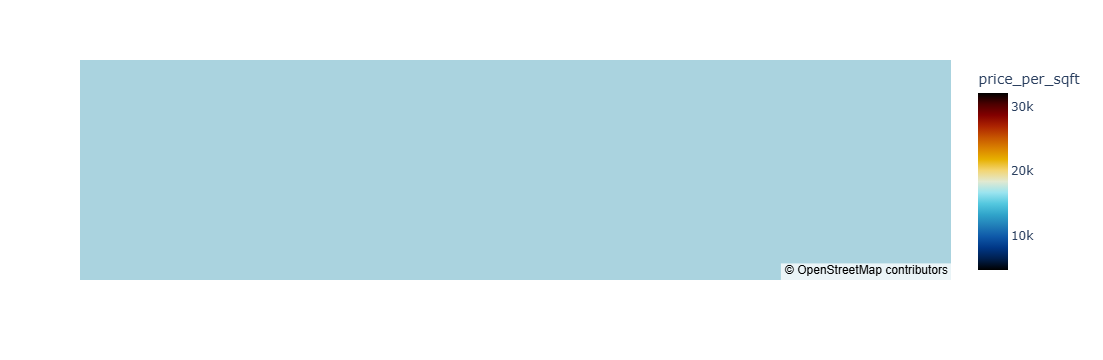

In [21]:
fig = px.scatter_map(
    group_df,
    lat="latitude",
    lon="longitude",
    color="price_per_sqft",
    size="built_up_area",
    color_continuous_scale=px.colors.cyclical.IceFire,
    zoom=10,
    map_style="open-street-map",
    hover_name=group_df.index
)

fig.show()

In [22]:
print(group_df[['latitude', 'longitude']].head(10))

print(group_df[['latitude', 'longitude']].isnull().sum())

print(group_df[['latitude', 'longitude']].describe())

             latitude  longitude
sector                          
gwal pahari   28.4484    77.0210
manesar       28.3515    76.9428
sector 1      28.3663    76.9456
sector 102    28.4750    76.9715
sector 103    28.4949    76.9845
sector 104    28.4788    76.9960
sector 105    28.4952    77.0114
sector 106    28.5007    77.0003
sector 107    28.5052    76.9729
sector 108    28.5134    76.9830
latitude     0
longitude    0
dtype: int64
         latitude   longitude
count  105.000000  105.000000
mean    28.439930   77.022443
std      0.042648    0.052935
min     28.351500   76.897000
25%     28.405000   76.983000
50%     28.437500   77.023300
75%     28.473800   77.062800
max     28.528700   77.110500


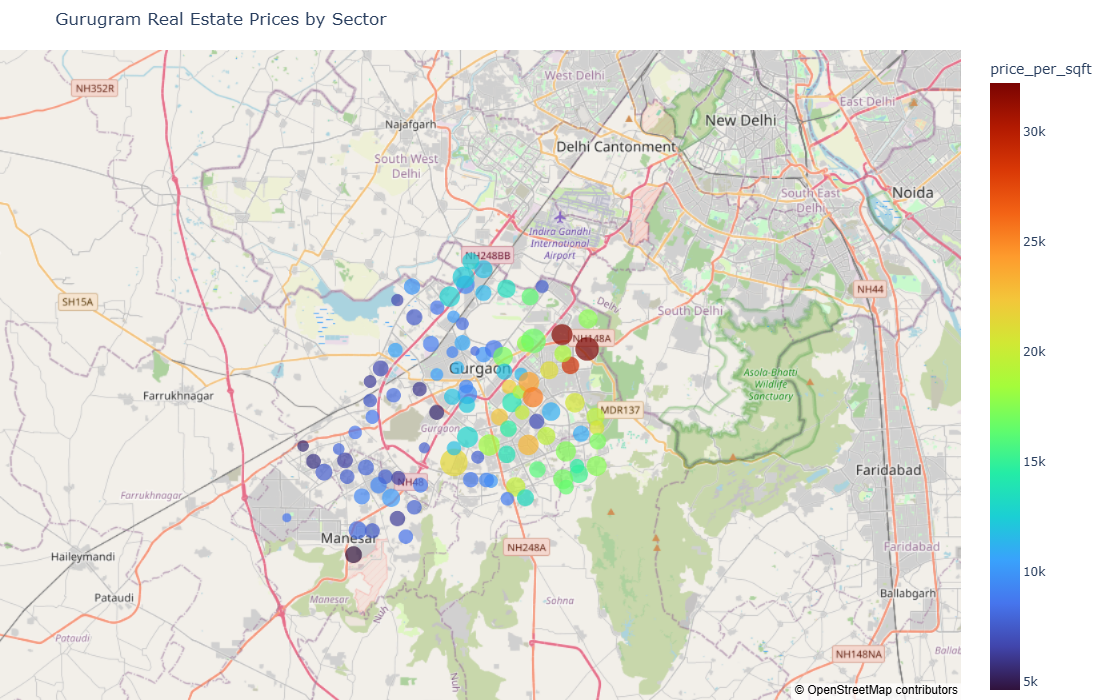

In [25]:
import plotly.express as px

map_df = group_df.reset_index()

fig = px.scatter_map(
    map_df,
    lat="latitude",
    lon="longitude",
    color="price_per_sqft",
    size="built_up_area",
    hover_name="sector",
    hover_data={
        "price": True,
        "price_per_sqft": True,
        "built_up_area": True,
        "latitude": False,
        "longitude": False
    },
    color_continuous_scale="Turbo",
    zoom=10,
    center={"lat": 28.46, "lon": 77.03},
    map_style="open-street-map",
    title="Gurugram Real Estate Prices by Sector"
)

fig.update_layout(
    height=700,
    margin={"r": 0, "t": 50, "l": 0, "b": 0}
)

fig.show()

In [27]:
new_df.to_csv('data_viz1.csv',index=False)

In [29]:
df1 = pd.read_csv('gurgaon_properties.csv')

In [31]:
df1.head()

,property_name,property_type,society,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,address,floorNum,facing,agePossession,nearbyLocations,description,furnishDetails,features,rating
0,5 Bedroom House for sale in Sector 21A Faridabad,house,independent,5.70,105751.0,539.0,Plot area 539(50.07 sq.m.),5.0,4.0,2,"store room,pooja room,servant room","Sector 21A Faridabad, Gurgaon, Haryana",2.0,NaN,5 to 10 Year Old,NaN,"Hi, we have an independent house/villa availab...","['1 Water Purifier', '5 Fan', '1 Exhaust Fan',...","['Private Garden / Terrace', 'Park', 'Visitor ...",NaN
1,3 BHK Flat in Sector 102 Gurgaon,flat,adani oyster greens,1.90,10058.0,1889.0,Carpet area: 1889 (175.49 sq.m.),3.0,3.0,3+,"pooja room,study room,store room","1456, Sector 102 Gurgaon, Gurgaon, Haryana",9.0,North-East,1 to 5 Year Old,"['MSK bedding products', 'INOX Gurgaon Dreamz ...",Looking for a 3 bhk property for sale in gurga...,"['8 Fan', '7 Light', '1 Modular Kitchen', '1 C...",NaN,"['Environment4 out of 5', 'Lifestyle4.5 out of..."
2,3 BHK Flat in Dwarka Expressway Gurgaon,flat,ramprastha city,1.30,9027.0,1440.0,Super Built up area 1440(133.78 sq.m.),3.0,3.0,2,not available,"Dwarka Expressway Gurgaon, Gurgaon, Haryana",3.0,NaN,By 2023,"['Raheja Mall', 'HUDA Market, Sector 14', 'Gur...",We are the proud owners of this 3 bhk apartmen...,[],NaN,NaN
3,2 Bedroom House for sale in Mohan Nagar,house,independent,0.42,4666.0,900.0,Plot area 900(83.61 sq.m.),2.0,2.0,1,not available,House No 15 N Block Gali No 2 Mohan Nagar Maru...,1.0,NaN,1 to 5 Year Old,"['Astha Hospital', 'SPAZE BUSINESS PARK', 'Kor...","This 2 bhk house for sale in mohan nagar, a we...",NaN,NaN,NaN
4,2 BHK Flat in Sector 99 Gurgaon,flat,assotech blith,0.92,6739.0,1365.0,Super Built up area 1365(126.81 sq.m.),2.0,2.0,3+,not available,"Sector 99 Gurgaon, Gurgaon, Haryana",22.0,NaN,By 2023,"['Huda Metro Station (Gurugram)', 'Dwarka Expr...",Right on dwarkaexpressway near metro station s...,[],"['Private Garden / Terrace', 'Lift(s)', 'Swimm...","['Environment4.5 out of 5', 'Safety4.5 out of ..."


In [33]:
wordcloud_df = df1.merge(df, left_index=True, right_index=True)[['features','sector']]

In [35]:
wordcloud_df.head()

,features,sector
0,"['Private Garden / Terrace', 'Park', 'Visitor ...",sector 102
1,NaN,dwarka expressway
2,NaN,sector 99
3,NaN,sector 70a
4,"['Private Garden / Terrace', 'Lift(s)', 'Swimm...",sector 92


In [37]:
import ast
from collections import Counter

main = []

for item in wordcloud_df['features'].dropna():
    try:
        features_list = ast.literal_eval(item)
        if isinstance(features_list, list):
            main.extend(features_list)
    except (ValueError, SyntaxError):
        continue

# All unique amenities with their frequencies
amenities_count = Counter(main)

amenities_df = pd.DataFrame(
    amenities_count.items(),
    columns=['Amenity', 'Frequency']
).sort_values(by='Frequency', ascending=False)

# Display ALL amenities
display(amenities_df)

,Amenity,Frequency
1,Park,2597
14,Maintenance Staff,2313
6,Lift(s),2216
2,Visitor Parking,2188
15,Water Storage,2061
11,Feng Shui / Vaastu Compliant,1881
13,Intercom Facility,1851
12,Security / Fire Alarm,1758
10,Fitness Centre / GYM,1736
28,Club house / Community Center,1723


In [39]:
%pip install wordcloud matplotlib

Note: you may need to restart the kernel to use updated packages.


In [55]:
wordcloud_df.to_csv("wordcloud_data.csv", index=False)

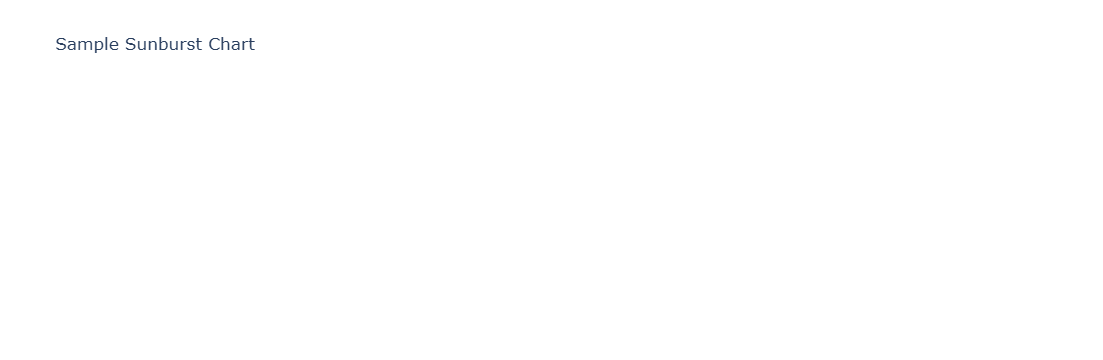

In [41]:
data = dict(
    names=["A", "B", "C", "D", "E", "F"],
    parents=["", "", "", "A", "A", "C"],
    values=[10, 20, 30, 40, 50, 60],
)

fig = px.sunburst(
    df1,
    names='property_type',
    values='price_per_sqft',
    parents='bedRoom',
    title="Sample Sunburst Chart"
)
fig.show()

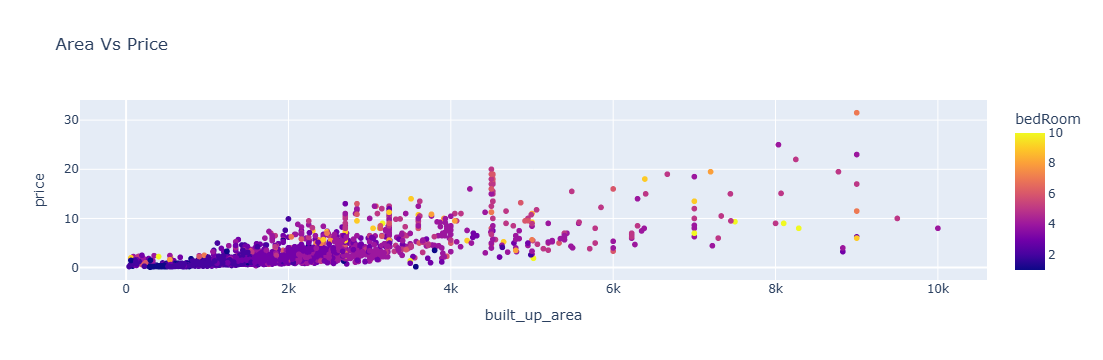

In [43]:
fig = px.scatter(df, x="built_up_area", y="price", color="bedRoom", title="Area Vs Price")

# Show the plot
fig.show()
